# NB0 · Exploratory Data Analysis

**Machine Learning I · Group Project 2026-27 · The Guild of Gentle Landings**

Goal: understand `learn.csv` before touching it. This notebook does **not** change the data and does **not** train models. Every finding should lead to a decision (or at least a question) for NB1.

## 0. Imports and data loading

In [73]:
%pip install missingno

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from pathlib import Path

# Support running from the notebook folder or the VS Code workspace root.
data_dirs = [
    Path.cwd(),
    Path.cwd() / "Student_files",
    Path.cwd() / "Machine-Learning-project---Plane-" / "Student_files",
]
learn_path = next((folder / "learn.csv" for folder in data_dirs
                   if (folder / "learn.csv").is_file()), None)
if learn_path is None:
    raise FileNotFoundError(
        "learn.csv was not found. Put it beside this notebook or in Student_files. "
        f"Current working directory: {Path.cwd()}"
    )

learn_data = pd.read_csv(learn_path)
print(f"Loaded {learn_path}: {learn_data.shape[0]:,} rows, {learn_data.shape[1]} columns")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Loaded /Users/joaquimtomasplacenciadefreitas/Desktop/NOVA IMS/machine learnig/DATA AVIONARIES:PROJECT/Machine-Learning-project---Plane-/Student_files/learn.csv: 16,979 rows, 42 columns


## 1. First look at the data

Shape, first rows, data types and number of missing values per column.

In [74]:
print(learn_data.head())
print(learn_data.shape)

   row_id  ev_year  ev_month ev_country ev_dow  ev_hour light_cond  \
0  A00001     2018         9        USA     Th     19.0       DAYL   
1  A00002     2011         7        USA     Sa     17.0       DAYL   
2  A00004     2013         7        USA     Su     22.0       DAYL   
3  A00005     2019         9        USA     Fr      0.0       DAYL   
4  A00006     2008         4        USA     Su      1.0       DAYL   

  wx_cond_basic sky_cond_ceil sky_cond_nonceil  ... total_seats  acft_year  \
0           VMC          NONE             CLER  ...         2.0     1956.0   
1           VMC          NONE             CLER  ...         2.0        NaN   
2           VMC           UNK              FEW  ...         2.0        NaN   
3           VMC           BKN              NaN  ...         4.0     1976.0   
4           VMC          NONE             CLER  ...         4.0        NaN   

   eng_type  carb_fuel_injection  eng_power  pilot_age  pilot_sex  \
0       REC                 CARB        N

In [75]:
missing_count = learn_data.isnull().sum()
print(missing_count)

row_id                    0
ev_year                   0
ev_month                  0
ev_country                0
ev_dow                    0
ev_hour                  19
light_cond               26
wx_cond_basic            19
sky_cond_ceil          2002
sky_cond_nonceil       2821
gust_ind                  0
sky_ceil_ht               0
vis_sm                  721
wx_temp                   0
wx_temp_c                 0
wx_dew_pt                 0
wind_dir_deg              0
wind_vel_kts           3603
gust_kts                  0
altimeter                 0
apt_dist                  0
apt_elev               5712
far_part                  1
acft_category             0
homebuilt                 0
fixed_retractable         0
type_fly                787
flt_plan_filed          242
second_pilot           1184
acft_make                 1
ifr_equipped_cert         0
num_eng                 485
total_seats            1206
acft_year              6816
eng_type                602
carb_fuel_injection 

In [76]:
print(learn_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16979 entries, 0 to 16978
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   row_id               16979 non-null  object 
 1   ev_year              16979 non-null  int64  
 2   ev_month             16979 non-null  int64  
 3   ev_country           16979 non-null  object 
 4   ev_dow               16979 non-null  object 
 5   ev_hour              16960 non-null  float64
 6   light_cond           16953 non-null  object 
 7   wx_cond_basic        16960 non-null  object 
 8   sky_cond_ceil        14977 non-null  object 
 9   sky_cond_nonceil     14158 non-null  object 
 10  gust_ind             16979 non-null  object 
 11  sky_ceil_ht          16979 non-null  int64  
 12  vis_sm               16258 non-null  float64
 13  wx_temp              16979 non-null  int64  
 14  wx_temp_c            16979 non-null  float64
 15  wx_dew_pt            16979 non-null 

**Interpretation:** _(write here: which columns have missing values, which dtypes look wrong, etc.)_

## 2. Missing values: counts and percentages

We keep only the columns with at least one missing value and compute the percentage of missing rows per column.

In [77]:
missing_filtered = missing_count[missing_count > 0].sort_values(ascending=True)
# There are several missing values

# Percentage of missing values per column
missing_percentage = (missing_filtered / len(learn_data)) * 100
missing_info = pd.DataFrame({
    'missing count': missing_count,
    'percentage (%)': missing_percentage
}).sort_values(by='percentage (%)', ascending=False)

print(missing_info[missing_info['missing count'] > 0])

# Column with the highest missing value level: acft_year

                     missing count  percentage (%)
acft_year                     6816       40.143707
apt_elev                      5712       33.641557
carb_fuel_injection           3608       21.249779
wind_vel_kts                  3603       21.220331
sky_cond_nonceil              2821       16.614642
pilot_sex                     2696       15.878438
sky_cond_ceil                 2002       11.791036
eng_power                     1801       10.607221
total_seats                   1206        7.102892
second_pilot                  1184        6.973320
type_fly                       787        4.635138
vis_sm                         721        4.246422
eng_type                       602        3.545556
num_eng                        485        2.856470
flt_plan_filed                 242        1.425290
pilot_age                      122        0.718535
pilot_med_certf                119        0.700866
light_cond                      26        0.153130
ev_hour                        

**After this initial analysis it is possible to observe taht the column with the highest missing value percentage is 'acft_year'. Based on this, it is important to understand what is going to be the next decision,for NB1, e.g. imputation vs. dropping vs. "was missing" flag**

## 3. Visualizing missing values

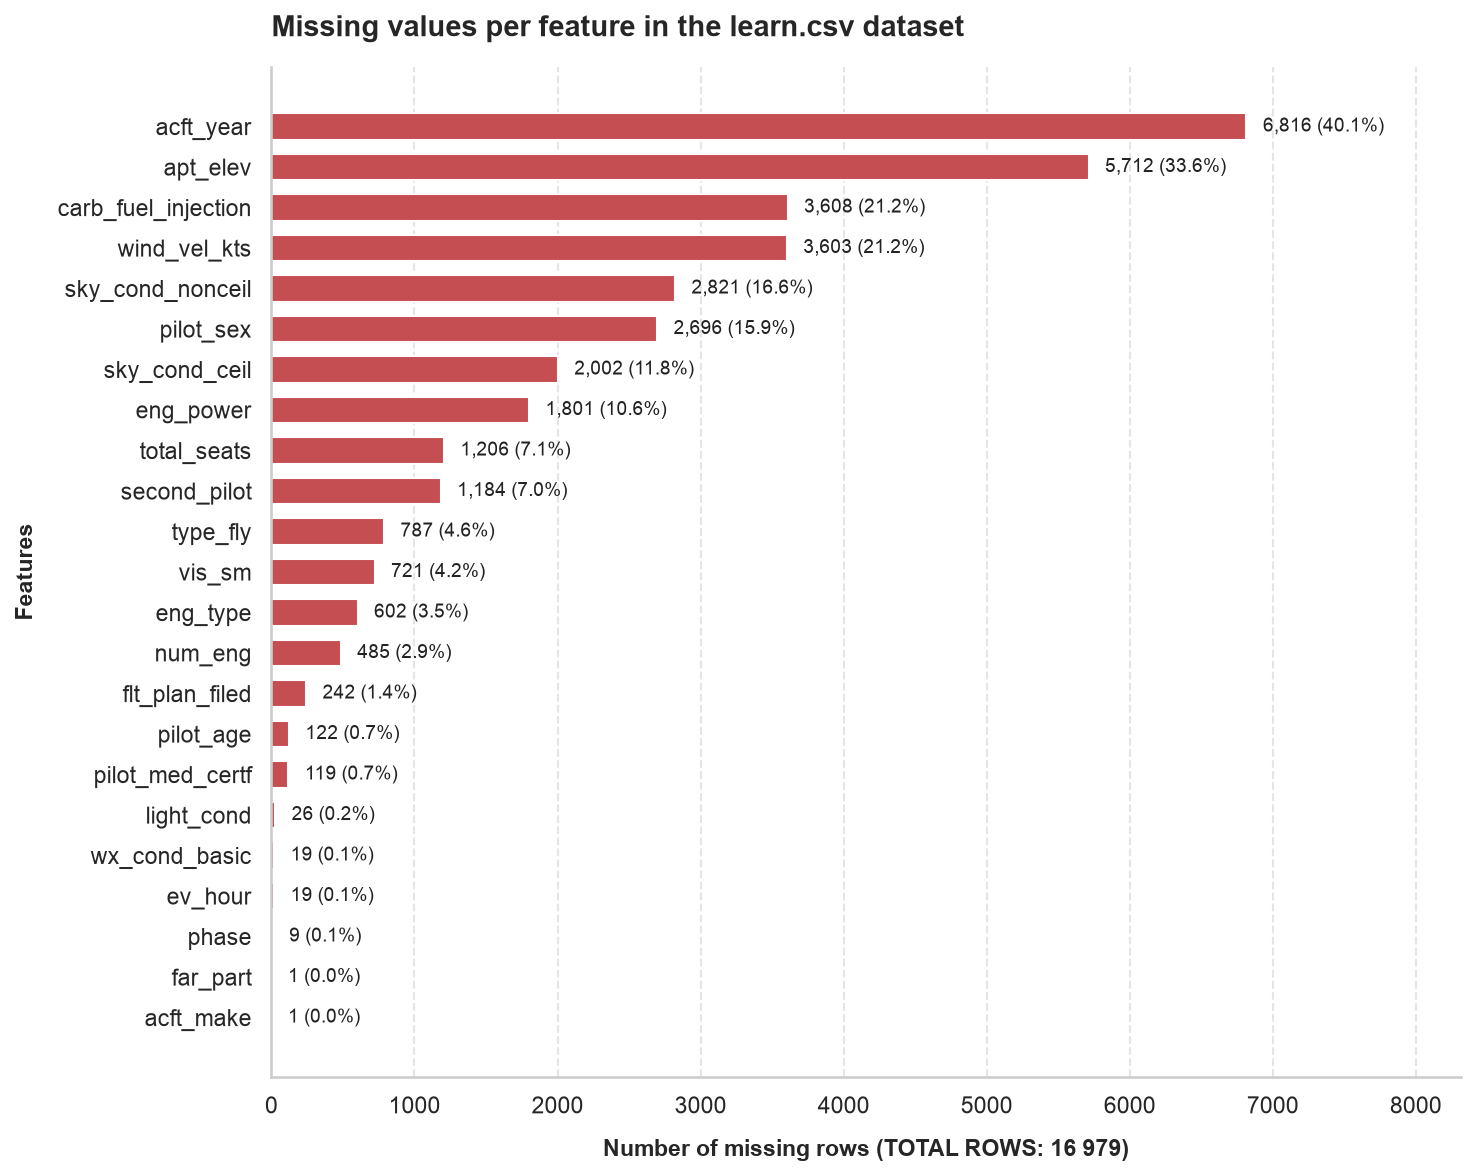

In [78]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)

bars = ax.barh(missing_filtered.index, missing_filtered.values,
               color='r',
               height=0.65)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')
ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.yaxis.grid(False)

# Annotating each bar
for bar, count, pct in zip(bars, missing_filtered.values, missing_percentage.values):
    width = bar.get_width()
    ax.text(width + 80, bar.get_y() + bar.get_height()/2, f" {count:,} ({pct:.1f}%)",
            va='center', ha='left', fontsize=9, color='#222222')

# Titles, labels and boundaries
ax.set_title('Missing values per feature in the learn.csv dataset', fontsize=14, fontweight='bold', pad=15, loc='left')
ax.set_xlabel('Number of missing rows (TOTAL ROWS: 16 979)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Features', fontsize=11, fontweight='bold', labelpad=10)
ax.set_xlim(0, max(missing_filtered.values) * 1.22)
plt.tight_layout()
plt.show()

**Interpretation:** As it was observed previously, the column with the highest missing percentage is 'acft_year'(40%), followed by, 'apt_elev' with 34%, carb_fuel_injection and wind_vel_kts in third with 20%.However some of these columns may contain vital information therefore, understanding why these values are missing is essential before dealing with them.

In [79]:
def missing_level(df,low=5,high=20):
    total_rows=len(df)
    missing_count=df.isnull().sum()
    missing_pct=(missing_count/total_rows)*100
    summary= pd.DataFrame({
        'missing_count': missing_count,
        'missing_pct': missing_pct,
        'dtype': df.dtypes,
    })

    conditions = [
        (summary["missing_pct"]==0),
        (summary["missing_pct"]>0) & (summary["missing_pct"] <= low),
        (summary["missing_pct"]> low) & (summary["missing_pct"]<=high),
        (summary["missing_pct"]>high),
    ]

    choices=[
        "Complete (0%)",
        f"Low (<= {low}%)",
        f"Intermediate ({low}% - {high}%)",
        f"High (> {high}%)"

    ]
    summary['missing_level']=np.select(conditions,choices,default='Unknown')
    missing_summary = summary[summary["missing_count"] > 0].sort_values(
        by="missing_pct", ascending=False
    )
    return missing_summary


missing_df = missing_level(learn_data, low=5.0, high=20.0)
print(missing_df.sample(10))



                 missing_count  missing_pct    dtype  \
eng_type                   602     3.545556   object   
wind_vel_kts              3603    21.220331  float64   
pilot_med_certf            119     0.700866   object   
second_pilot              1184     6.973320   object   
apt_elev                  5712    33.641557  float64   
ev_hour                     19     0.111903  float64   
num_eng                    485     2.856470  float64   
vis_sm                     721     4.246422  float64   
acft_year                 6816    40.143707  float64   
eng_power                 1801    10.607221  float64   

                               missing_level  
eng_type                       Low (<= 5.0%)  
wind_vel_kts                  High (> 20.0%)  
pilot_med_certf                Low (<= 5.0%)  
second_pilot     Intermediate (5.0% - 20.0%)  
apt_elev                      High (> 20.0%)  
ev_hour                        Low (<= 5.0%)  
num_eng                        Low (<= 5.0%)  
vis_sm 

**Values with high missing rate require a more delicate approach meanwhile values with low missing value can be dealt with just by computing the median or KNN.On the other hand, intermediate misisng can be solved via Median/mode imputation combined with missing flags.**


## 4. Sentinel strings in categorical columns

Missing values are not always empty cells: codes such as `UNK` can hide them. We scan every categorical column for common sentinel terms.

In [80]:
sent_term = ['UNK', 'UNKNOWN', 'N/A', 'MISSING', '?','NR']

sent_summary = []
for col in learn_data.select_dtypes(include=['object', 'category']).columns:
    col_str = learn_data[col].astype(str).str.upper()
    for term in sent_term:
        count = (col_str == term).sum()
        if count > 0:
            sent_summary.append({'Feature': col, 'Sentinel Value': term, 'Count': count})

pd.DataFrame(sent_summary)

,Feature,Sentinel Value,Count
0,light_cond,NR,32
1,wx_cond_basic,UNK,68
2,sky_cond_ceil,UNK,95
3,sky_cond_nonceil,UNK,157
4,far_part,UNK,4
5,type_fly,UNK,21
6,flt_plan_filed,UNK,754
7,acft_make,UNKNOWN,4
8,eng_type,UNK,17
9,pilot_med_certf,UNK,92


**Interpretation:** _(write here: note that the data dictionary also uses `NR` and `Unk`, and that `NONE` can be a real category in some columns)_

**The next step consists f understanding why are there missing values**


WE HAVE UNDERSTOOD WHAT VALUES ARE MISSING 
 NOW WE SHALL FOCUS ON WHY THOSE VALUES ARE MISSING
ARE THEY MISSING IN THE SAME ROWS ? 
IS THERE ANY ROW THAT MAKES MISSING HIGHER
THERE ARE AS WELL IMPOSSIBLE VALUES MENTIONED IN THE PDF WE HAVE TO CHECK THEM OUT 

 The PDF includes a passage numbered “5.2.1” saying all submissions must include seat_vintage_ratio = total_seats / acft_year
 It sits oddly in the document: the numbering doesn’t match the surrounding sections, 
 and its claim that this ratio is linked to slower evacuation is not credible. 
 Since acft_year is roughly 1950-2023, the ratio is essentially just total_seats scaled by a nearly constant number. 
 I’d confirm with your instructor that it’s a real requirement before building around it

**LETS TRY AND UNDERSTAND WHY ARE THE VALUES MISSING**


TEMPORAL RECORD-KEEPING SHIFT (acft_year missingness by ev_year)"


In [81]:
print("1. TEMPORAL RECORD-KEEPING SHIFT (acft_year missingness by ev_year)")

acft_year_trend= (
    learn_data.groupby('ev_year')['acft_year'].apply(lambda x: x.isnull().mean()*100).reset_index()

)
acft_year_trend.columns=['ev_year','missing_acft_year_pct']
print(acft_year_trend.to_string(index=False))



1. TEMPORAL RECORD-KEEPING SHIFT (acft_year missingness by ev_year)
 ev_year  missing_acft_year_pct
    2008              99.921445
    2009              99.917492
    2010              99.498747
    2011              97.306122
    2012              89.433643
    2013              56.577646
    2014               4.809619
    2015               3.033268
    2016               2.213667
    2017               2.791625
    2018               2.105263
    2019               2.979146
    2020               3.153153
    2021               3.534304
    2022               3.451777
    2023               4.520990


FLIGHT PHASE vs AIRPORT ELEVATION MISSINGNESS (apt_elev)

In [82]:
apt_elev_phase= (
    learn_data.groupby('phase')['apt_elev'].agg(
        total_incidents='count',
        missing_count= lambda x: x.isnull().sum(),
        missing_pct= lambda x: x.isnull().mean()*100,

    )
    .sort_values(by='missing_pct',ascending=False).reset_index()
)

print(apt_elev_phase.to_string(index=False))


            phase  total_incidents  missing_count  missing_pct
          Enroute              829           1922    69.865503
      Maneuvering              722           1521    67.810967
            Other               10             20    66.666667
Emergency descent              102             65    38.922156
  Prior to flight               49             17    25.757576
         Standing              151             51    25.247525
          Takeoff             1578            449    22.150962
          Landing             4420           1015    18.675253
             Taxi              324             70    17.766497
    Initial climb             1424            292    17.016317
         Approach             1643            282    14.649351
  Pushback/towing               13              1     7.142857


**ENGINE TYPE vs CARBURETOR FUEL INJECTION APPLICABILITY**


In [83]:
carb_engine=learn_data.groupby('eng_type',dropna=False)['carb_fuel_injection'].agg(
    total_counts='size',
    missing_count= lambda x: x.isnull().sum(),
    missing_pct= lambda x: x.isnull().mean()*100
).reset_index()

print(carb_engine.to_string(index=False))


eng_type  total_counts  missing_count  missing_pct
    ELEC            10             10   100.000000
    GTFN             1              1   100.000000
      HR             1              1   100.000000
      LR             1              1   100.000000
    NONE            23             23   100.000000
     REC         14154           1289     9.106966
      TF           404            341    84.405941
      TJ            97             75    77.319588
      TP           861            662    76.887340
      TS           808            593    73.391089
     UNK            17             11    64.705882
     NaN           602            601    99.833887


In [84]:
wind_wx=(
    learn_data.groupby('wx_cond_basic',dropna=False)['wind_vel_kts'].agg(
        total_count='size',
        missing_count=lambda x: x.isnull().sum(),
        missing_pct=lambda x: x.isnull().mean() * 100,

    ).reset_index()
)
print(wind_wx.to_string(index=False))

wx_cond_basic  total_count  missing_count  missing_pct
          IMC          771            162    21.011673
          Unk           68             22    32.352941
          VMC        16121           3406    21.127722
          NaN           19             13    68.421053


In [85]:
print("5. SKY CONDITION CEILING vs NON-CEILING CROSSTAB")
sky_crosstab=pd.crosstab(
    learn_data['sky_cond_ceil'].fillna('MISSING'),
    learn_data['sky_cond_nonceil'].fillna('MISSING'),
    margins=True
).reset_index()
print(sky_crosstab.to_string(index=False))


5. SKY CONDITION CEILING vs NON-CEILING CROSSTAB
sky_cond_ceil  CLER  FEW  MISSING  OVCT  SCAT  UNK   All
          BKN   178  515     1149     9   684   39  2574
      MISSING   374  512      626     7   476    7  2002
         NONE  8654 1066       67    15   855    5 10662
          OVC   142  178      940   107   180   50  1597
          UNK    12   12        7     2    10   52    95
           VV    11    1       32     0     1    4    49
          All  9371 2284     2821   140  2206  157 16979


## 5. Target analysis: fatal

The target is `fatal`: 0 means no fatalities and 1 means at least one fatality. We examine the class balance without changing the data.

Counts:
fatal
0    14090
1     2889
Name: count, dtype: int64
Percentages:
fatal
0    82.98
1    17.02
Name: proportion, dtype: float64


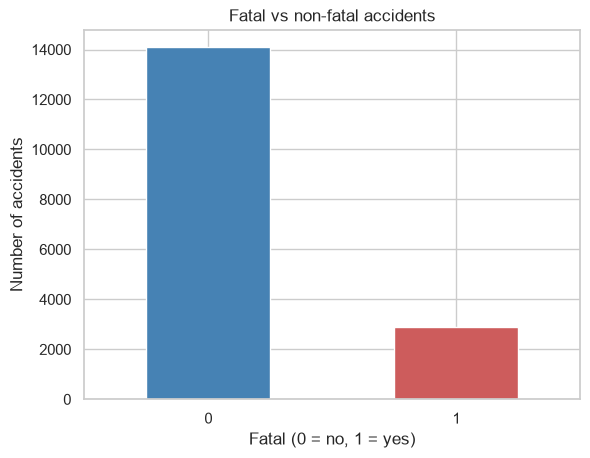

In [86]:
# 0 = non-fatal, 1 = fatal
counts = learn_data['fatal'].value_counts().sort_index()
percentages = learn_data['fatal'].value_counts(normalize=True).sort_index() * 100

print('Counts:')
print(counts)
print('Percentages:')
print(percentages.round(2))

counts.plot(kind='bar', color=['steelblue', 'indianred'])
plt.title('Fatal vs non-fatal accidents')
plt.xlabel('Fatal (0 = no, 1 = yes)')
plt.ylabel('Number of accidents')
plt.xticks(rotation=0)
plt.show()


**Interpretation:** There are 14,090 non-fatal accidents (82.98%) and 2,889 fatal accidents (17.02%), with no missing target values. The target is imbalanced: non-fatal accidents are about 4.9 times as common. A model that always predicts non-fatal would achieve 82.98% accuracy while detecting no fatal accidents. Later modelling should use a stratified split and assess fatal-class recall, precision and F1 alongside accuracy.

## 6. Data quality

Check duplicates, numeric ranges and category labels without changing the data. Suspicious values need review before cleaning in NB1.

In [87]:
# Check duplicates
print('Duplicate rows:', learn_data.duplicated().sum())
print('Duplicate row IDs:', learn_data['row_id'].duplicated().sum())

# Check numeric ranges for suspicious values
print(learn_data.describe().loc[['min', 'max']].T)

# Count some suspicious values (missing values are checked separately)
print('Pilot age outside 14-100:', ((learn_data['pilot_age'] < 14) | (learn_data['pilot_age'] > 100)).sum())
print('Aircraft year before 1900:', (learn_data['acft_year'] < 1900).sum())
print('Aircraft year after accident:', (learn_data['acft_year'] > learn_data['ev_year']).sum())
print('Seats zero or negative:', (learn_data['total_seats'] <= 0).sum())
print('Temperature above 60 C:', (learn_data['wx_temp_c'] > 60).sum())

# Inspect category labels
for col in learn_data.select_dtypes(include='object').columns:
    if col != 'row_id':
        print(col, ':', learn_data[col].dropna().unique())


Duplicate rows: 0
Duplicate row IDs: 0
                      min        max
ev_year            2008.0    2023.00
ev_month              1.0      12.00
ev_hour               0.0      23.00
sky_ceil_ht           0.0  241340.00
vis_sm                0.0    5000.00
wx_temp             -55.0    3005.00
wx_temp_c           -48.3    1651.70
wx_dew_pt           -39.0    3027.00
wind_dir_deg          0.0     360.00
wind_vel_kts          0.0     185.00
gust_kts              0.0    1077.00
altimeter             0.0    3052.98
apt_dist              0.0    7208.00
apt_elev           -224.0   33333.00
ifr_equipped_cert     0.0       1.00
num_eng               0.0       8.00
total_seats           0.0    8300.00
acft_year             0.0    2025.00
eng_power             0.0  264190.00
pilot_age             0.0     214.00
fatal                 0.0       1.00
Pilot age outside 14-100: 12
Aircraft year before 1900: 3
Aircraft year after accident: 86
Seats zero or negative: 37
Temperature above 60 C: 26
ev

**Interpretation:** No duplicate rows or row IDs were found. Suspicious values include pilot age 214, aircraft year 0, 8,300 seats and temperature 1,651.7 C. Check whether these are errors or special codes before handling them in NB1. Category labels mix capitalization, such as `AIR`/`air` and `Y`/`y`; these should be standardized in NB1. Negative airport elevation and zero engines can be valid. The thresholds above flag records for review rather than automatically marking them invalid.

## 7. Feature distruibition
Explore numeric values and category frequencies to identify common patterns, skewed distributions and potential outliers.

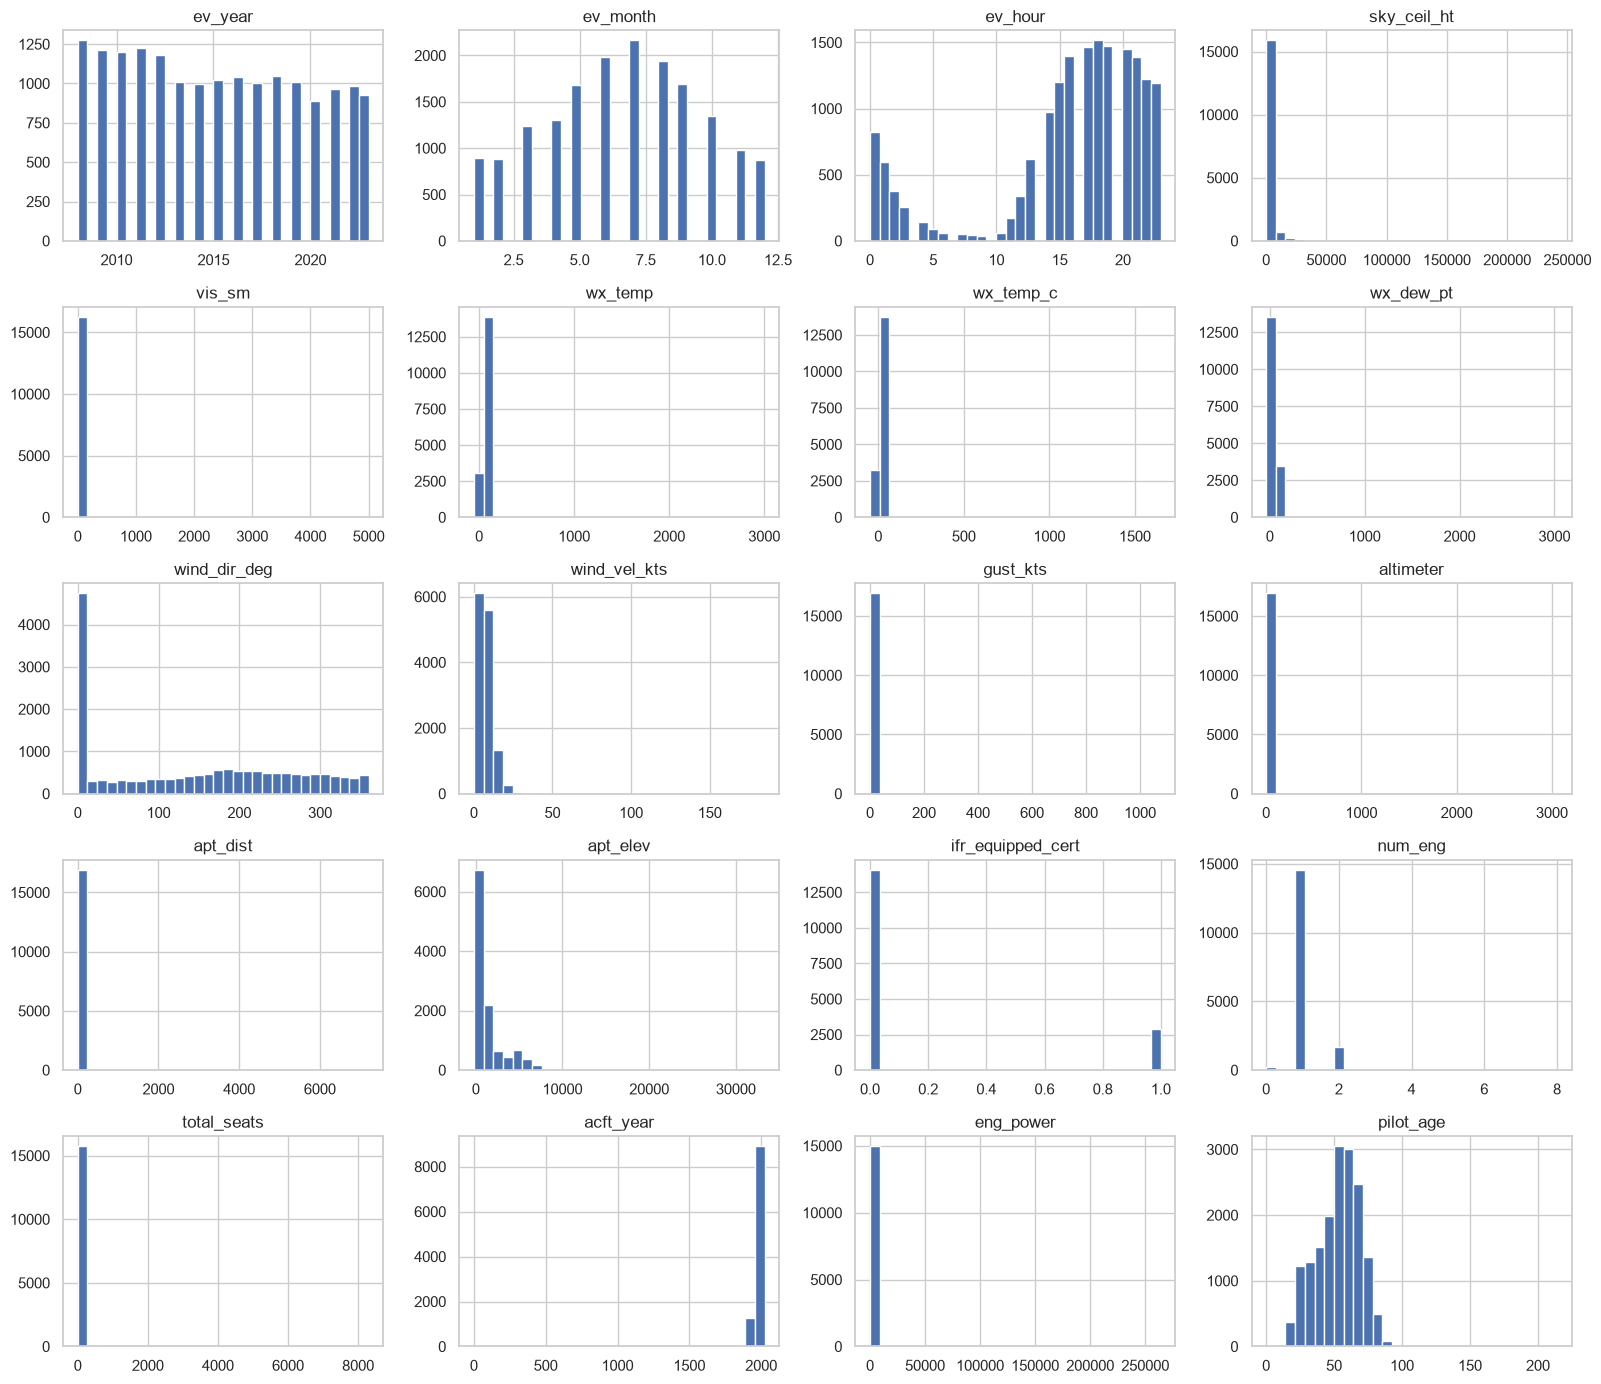

In [88]:
#numerical features distribution
learn_data.drop(columns='fatal').hist(bins=30, figsize=(16, 14))
plt.tight_layout()
plt.show()

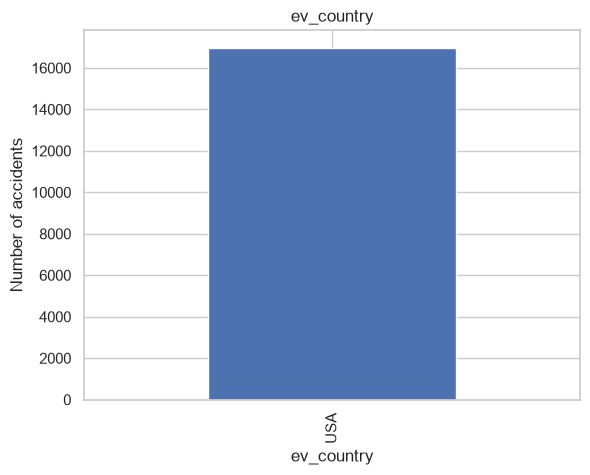

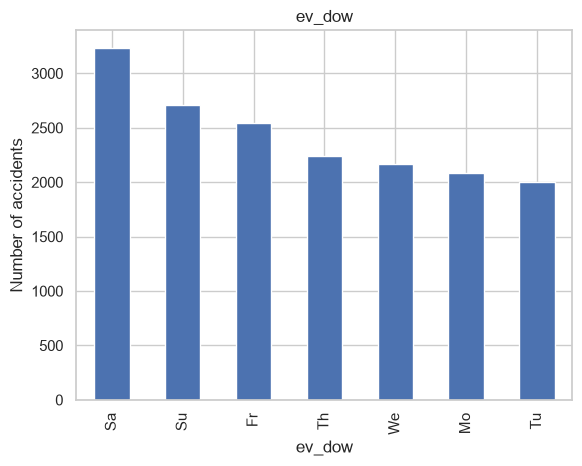

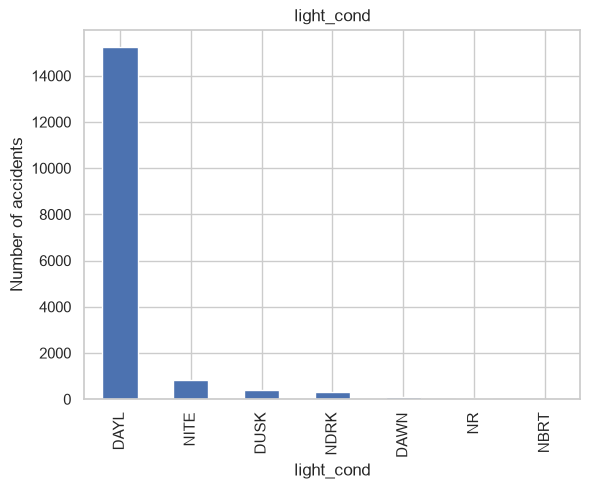

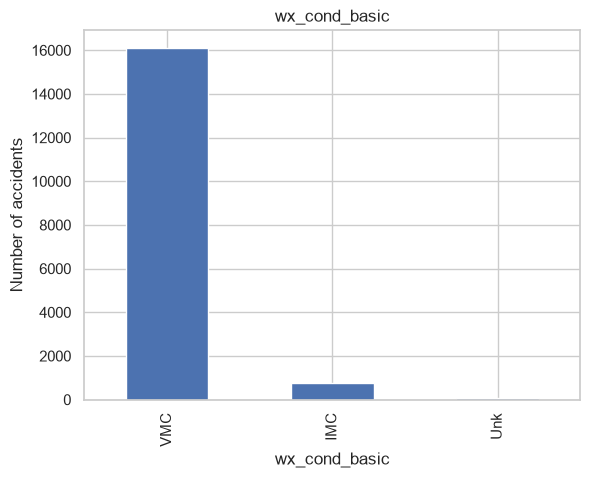

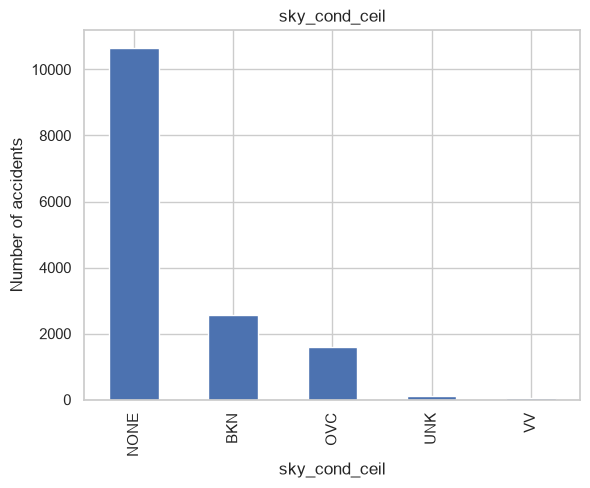

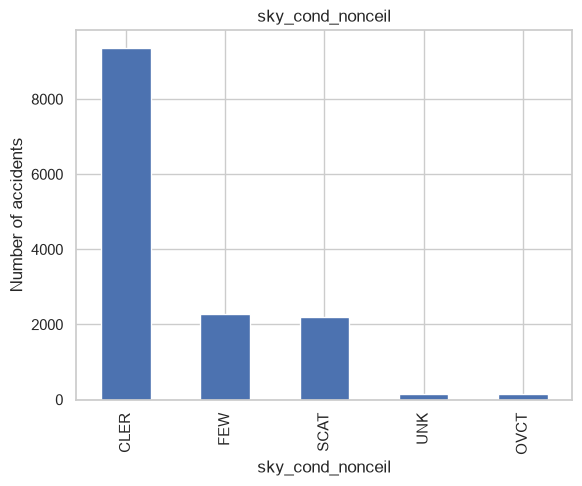

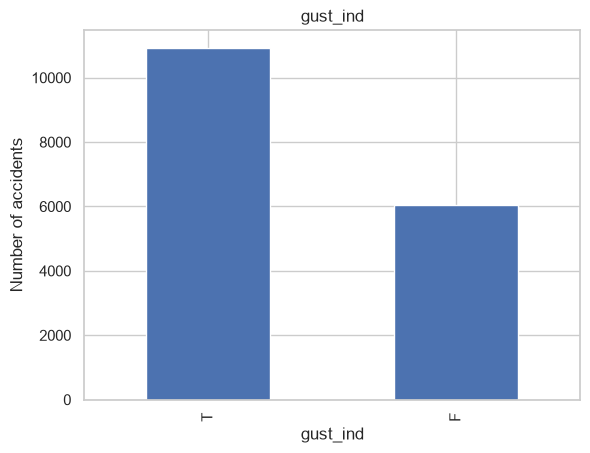

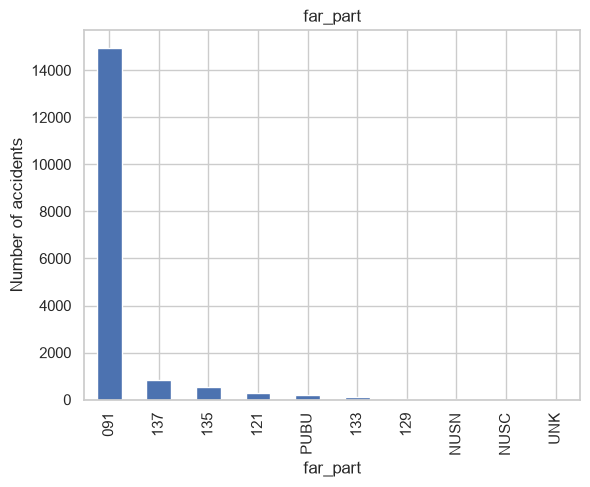

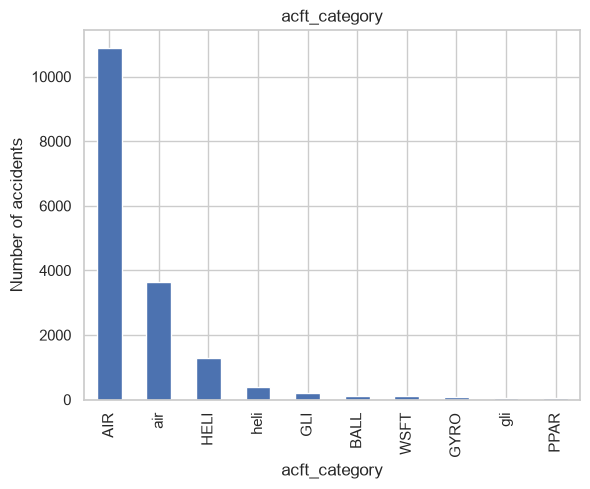

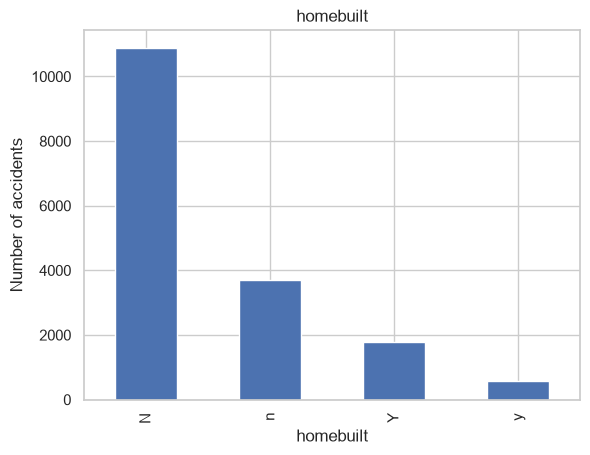

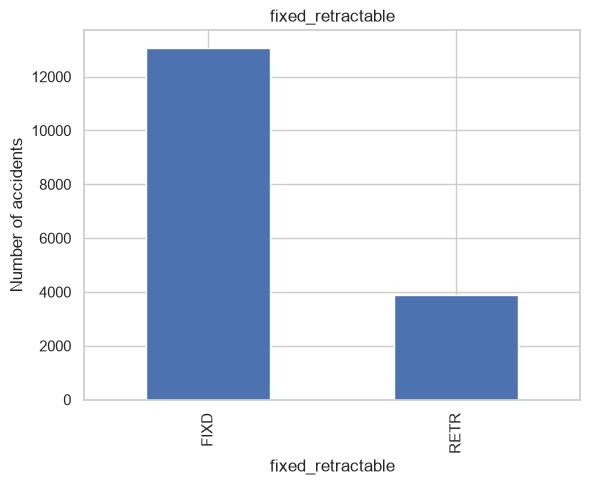

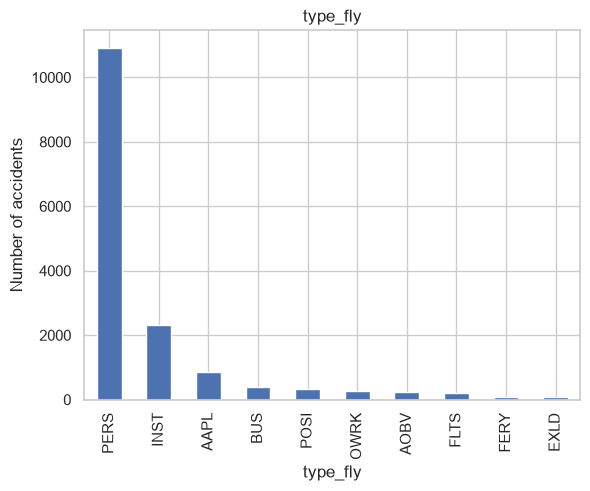

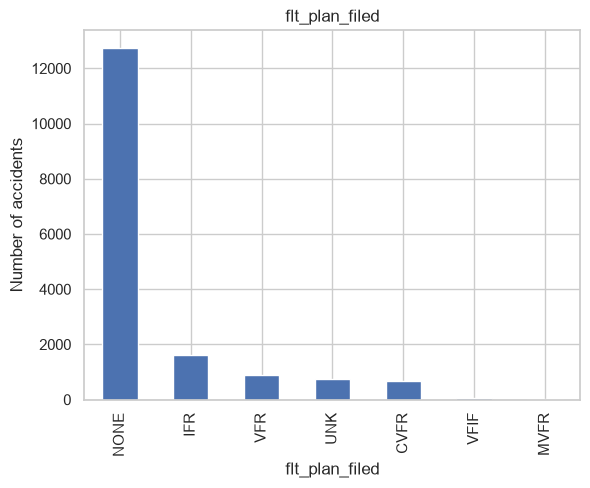

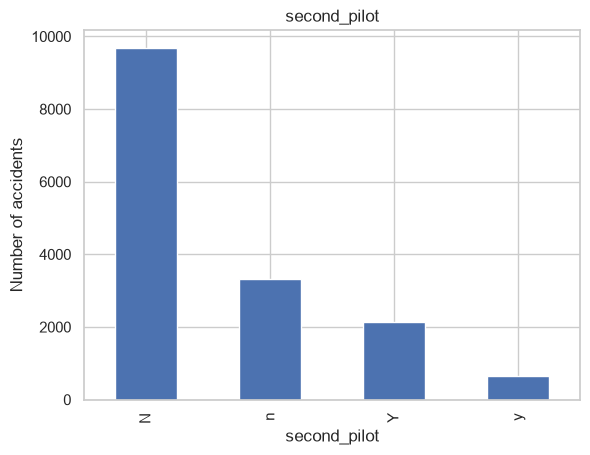

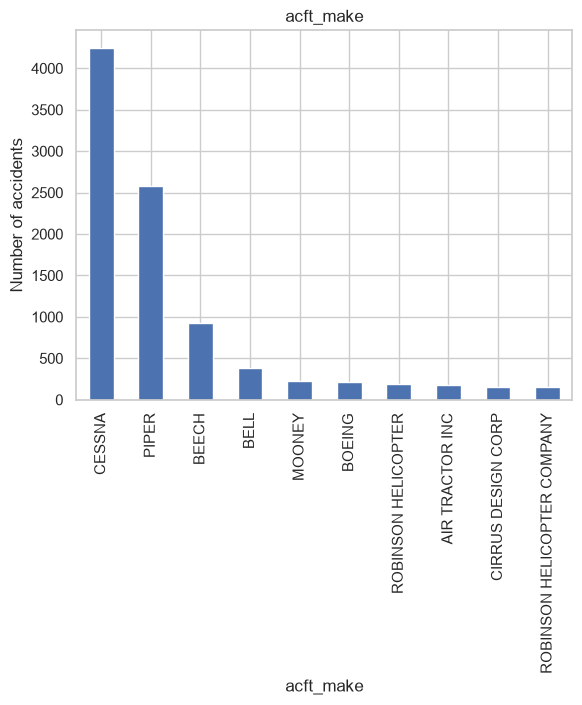

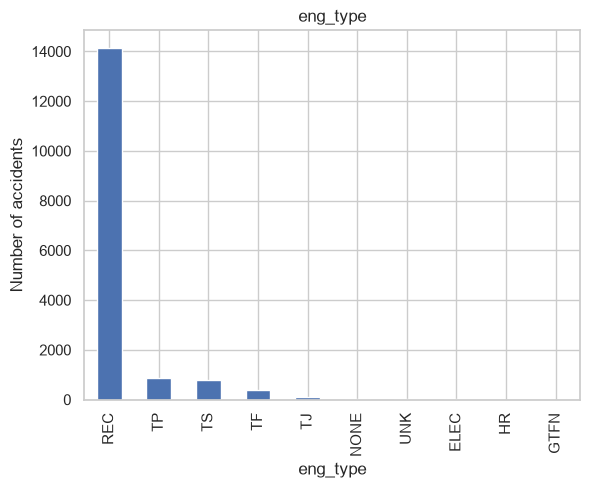

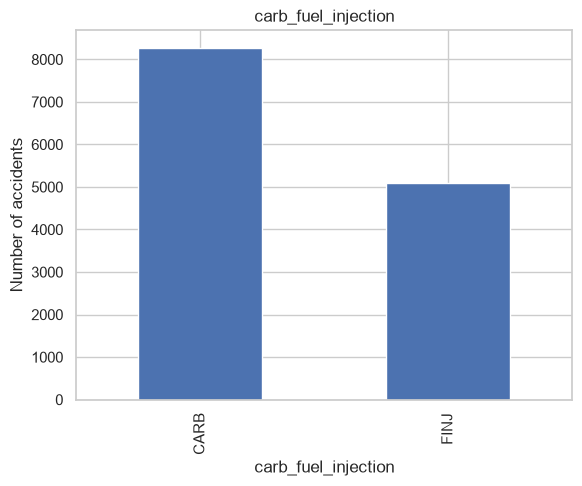

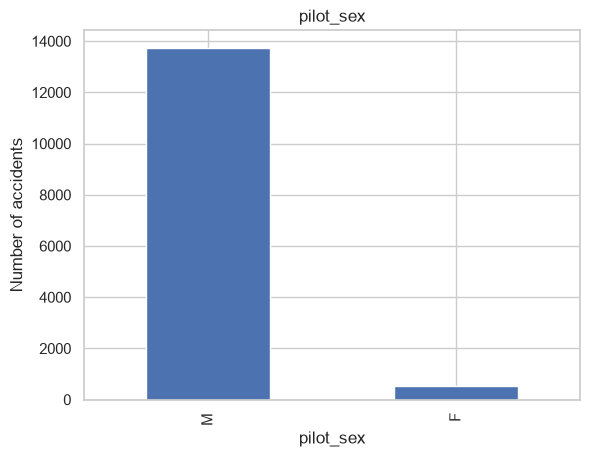

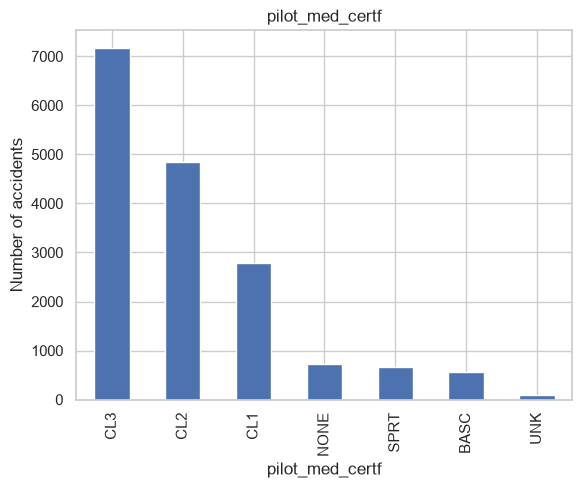

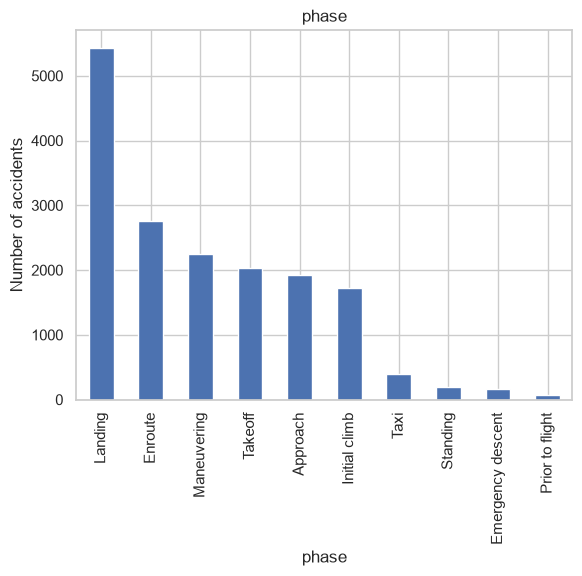

In [89]:
#categorical features distribution
for col in learn_data.select_dtypes(include='object').columns:
    if col != 'row_id':
        learn_data[col].value_counts().head(10).plot(kind='bar')
        plt.title(col)
        plt.ylabel('Number of accidents')
        plt.show()

## 8. Relationships with fatal

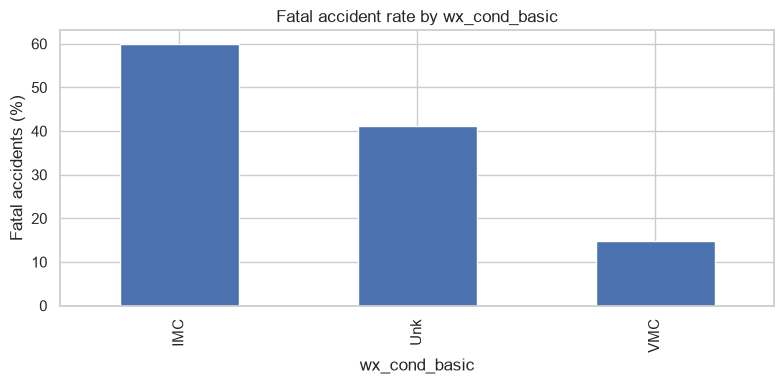

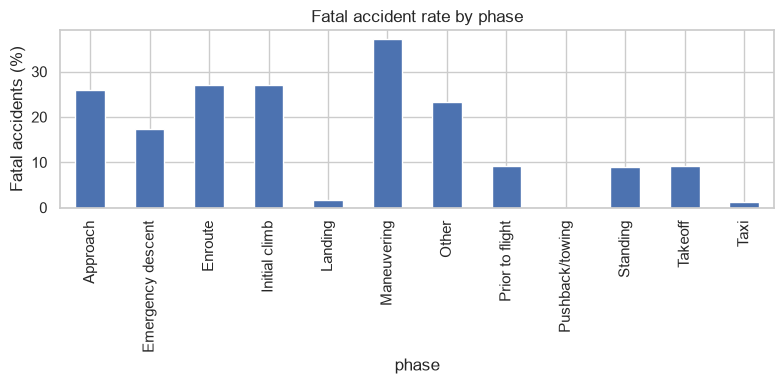

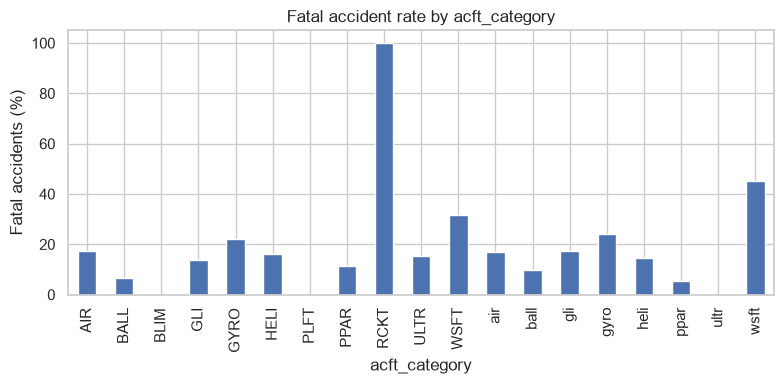

In [90]:
for col in ['wx_cond_basic', 'phase', 'acft_category']:
    rates = learn_data.groupby(col)['fatal'].mean() * 100

    rates.plot(kind='bar', figsize=(8, 4))
    plt.title('Fatal accident rate by ' + col)
    plt.ylabel('Fatal accidents (%)')
    plt.tight_layout()
    plt.show()

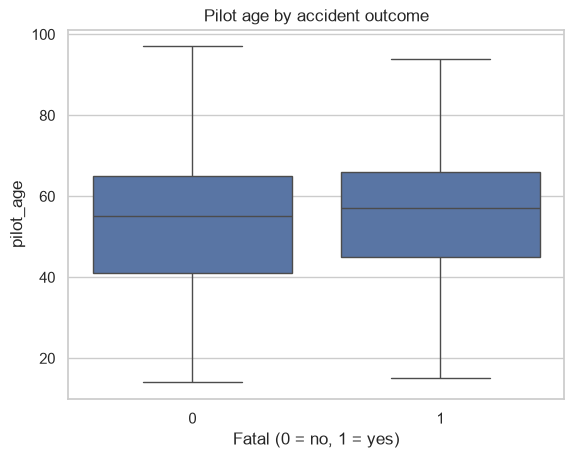

In [91]:
valid_ages = learn_data[learn_data['pilot_age'].between(14, 100)]

sns.boxplot(data=valid_ages, x='fatal', y='pilot_age')
plt.title('Pilot age by accident outcome')
plt.xlabel('Fatal (0 = no, 1 = yes)')
plt.show()

### Interpretation — feature distributions

Most aircraft have few seats, with a median of 4. Extreme values, such as 8,300 seats and temperatures above 1,600°C, need investigation in NB1. VMC weather and airplanes dominate the dataset. Labels such as AIR and air should be standardized.

### Interpretation — relationships with fatal

- Weather: 60.1% of recorded IMC accidents are fatal, compared with 14.8% of VMC accidents.
- Flight phase: Maneuvering has a fatality rate of 37.2%, compared with 1.7% during landing.
- Aircraft category: Compare rates carefully because some categories contain very few accidents.
- Pilot age: The median age is 57 for fatal accidents and 55 for non-fatal accidents. The distributions overlap substantially.

These comparisons describe recorded accidents, not risk per flight, and do not establish causes.

## Final conclusions

The dataset contains 16,979 accidents. Most are non-fatal (83%), so the target is imbalanced.

Missing values are substantial in some features, especially aircraft year (40.1%) and airport elevation (33.6%). Their patterns suggest that missingness is related to recording year, flight phase and engine type.

No duplicate rows or row IDs were found. However, suspicious numeric values and inconsistent capitalization in categorical labels need attention.

Fatality rates differ across weather conditions and flight phases. Pilot ages overlap substantially between fatal and non-fatal accidents. These findings show associations, not causes.

In NB1, investigate suspicious values, standardize categorical labels and choose suitable missing-value treatments. Fit preprocessing using training data only. Later modelling should account for class imbalance and evaluate fatal-class precision, recall and F1 alongside accuracy.